In [2]:
%load_ext autoreload
%autoreload 2
import sys 
sys.path.append('../')
import os
import torch
import torch.distributions as dist
import torch.nn as nn
from typing import List
from tqdm import tqdm
import matplotlib.pyplot as plt

from utils import view_image, load_cifar10_dataset, remove_module_prefix 

from torch.utils.tensorboard import SummaryWriter
from utils import load_mnist_dataset, flatten_image, unflatten_image, view_image
from unet import get_timestep_embedding, UNet
from simple_bridge import SimpleBrownianBridgeDiffusion
from unet_openai import create_openAI_Unet, create_model_and_diffusion
from mnist_denoising_diffusion_model_implementation import DiffusionModel
import torchvision.transforms as transforms
from PIL import Image

import matplotlib.pyplot as plt
import numpy as np

from torchmetrics.image.fid import FrechetInceptionDistance

In [3]:
def sample_batch(trainY, batch_size, device):
    indices = torch.randperm(len(trainY))[:batch_size]
    data = torch.stack([trainY[i] for i in indices]).to(device)

    return data

def process_image(image):
    image = (image - image.min()) / (image.max() - image.min())  # Normalize to [0, 1]
    image = (image * 255).clamp(0, 255).byte()  # Scale to [0, 255] and convert to uint8
    return image

In [4]:
trainY, testY = load_cifar10_dataset(root='/workspace/aim-bridges-data/cifar10', download=True)

Files already downloaded and verified
Files already downloaded and verified


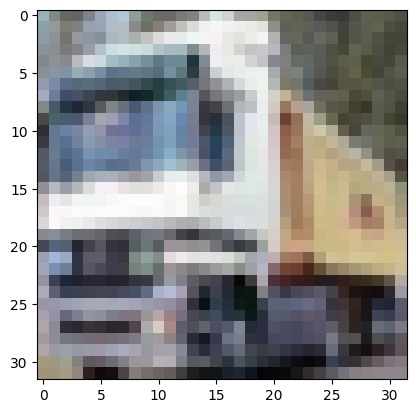

In [4]:
plt.imshow(trainY[1].permute(1, 2, 0))

In [90]:
def model_and_diffusion_defaults():
    """
    Defaults for image training.
    """
    return dict(
        image_size=32,
        num_channels=128,
        num_res_blocks=2,
        num_heads=4,
        num_heads_upsample=-1,
        attention_resolutions="16,8",
        dropout=0.3,
        learn_sigma=False,
        sigma_small=False,
        class_cond=False,
        diffusion_steps=1000,
        noise_schedule="linear",
        timestep_respacing="",
        use_kl=False,
        predict_xstart=False,
        rescale_timesteps=True,
        rescale_learned_sigmas=True,
        use_checkpoint=False,
        use_scale_shift_norm=True,
    )

model = create_model_and_diffusion(
        **model_and_diffusion_defaults()
    )

In [40]:
#model = UNet(in_ch=3)
model = create_openAI_Unet()
checkpoint_path = '/workspace/aim-bridges-models/bridge/checkpoints/batch_128_T_0.005_stoch_openAI_50M_checkpoint_n_batch_40000.pth'
#checkpoint_path = '/tmp/openai-2024-07-21-11-29-46-138137/model000000.pt'
print(f"Loading checkpoint '{checkpoint_path}'")
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(remove_module_prefix(checkpoint))

Loading checkpoint '/workspace/aim-bridges-models/bridge/checkpoints/batch_128_T_0.005_stoch_openAI_50M_checkpoint_n_batch_40000.pth'


<All keys matched successfully>

In [41]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'Total number of trainable parameters: {count_parameters(model)}')

Total number of trainable parameters: 52542979


100%|██████████| 1000/1000 [00:18<00:00, 53.95it/s]
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


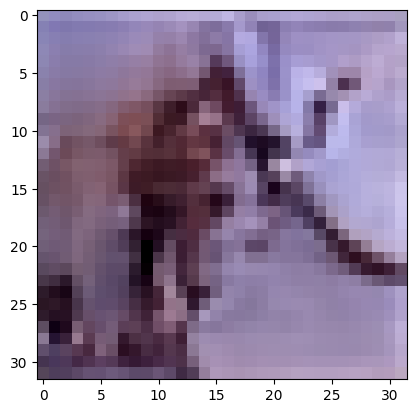

In [43]:
T = 0.005
diffusion_model = SimpleBrownianBridgeDiffusion(T, model, 'cuda', trainY, deterministic=True)
samples = diffusion_model.sampling(n_samples=2, image_channels=3, use_tqdm=True, n_steps=1000)
plt.imshow(samples.cpu()[0].permute(1, 2, 0))

In [44]:
# Set the output directory
output_dir = '/workspace/aim-bridges-img/generated_samples/40k_1k_0.005_det/'

if not os.path.exists(output_dir):
    os.makedirs(output_dir)

diffusion_model = SimpleBrownianBridgeDiffusion(T, model, 'cuda', trainY, deterministic=True)
n_samples = 50000
batch_size = 128
image_channels = 3

for i in range(n_samples // batch_size):  # Loop through batches of 32 samples
    batch_samples = diffusion_model.sampling(n_samples=batch_size, image_channels=image_channels, use_tqdm=True, n_steps=1000)
    samples_torch = torch.stack([process_image(samp) for samp in batch_samples])
    
    for j, sample in enumerate(samples_torch.cpu()):
        # convert to numpy array and change dtype
        sample_np = sample.permute(1, 2, 0).numpy()
        plt.imsave(os.path.join(output_dir, f'sample_{i*batch_size+j}.png'), sample_np)

100%|██████████| 1000/1000 [00:47<00:00, 21.27it/s]


In [45]:
img_dir = '/workspace/aim-bridges-img/generated_samples/40k_1k_0.005_det/'

# Get a list of all .png files in the directory
img_files = [f for f in os.listdir(img_dir) if f.endswith('.png')]

# Initialize an empty numpy array to store images
images = np.zeros((len(img_files), 32, 32, 3), dtype=np.uint8)

# Iterate over each image file and load it into the numpy array
for i, img_file in enumerate(img_files):
    img_path = os.path.join(img_dir, img_file)
    img = Image.open(img_path)
    img_array = np.array(img)
    images[i] = img_array[:,:,:3]

# Save the numpy array to a .npz file
np.savez('bridge_50000_40k_1k_0.005_det.npz', images=images)

In [37]:
# convert to numpy array and change dtype
#sample_np = sample.permute(1, 2, 0).cpu().numpy() * 255
#
# Convert the NumPy array to uint8
#sample_np = sample_np.astype(np.uint8)
plt.imsave(os.path.join(output_dir, f'sample_{i*128+j}.png'), sample_np)

In [38]:
test_sample = sample_batch(trainY=trainY, batch_size=50000, device='cpu')
train_sample_int  = torch.stack([process_image(samp) for samp in test_sample])

train_Y_int = torch.stack([process_image(samp) for samp in trainY])

In [59]:
train_Y_int.shape

torch.Size([50000, 3, 32, 32])

In [57]:
test_sample.shape

torch.Size([50000, 3, 32, 32])

In [8]:
fid = FrechetInceptionDistance().to('cuda')


In [7]:

model_sample_int = torch.stack([process_image(samp) for samp in samples])
fid.update(train_sample_int, real=True)
fid.update(model_sample_int, real=False)

NameError: name 'samples' is not defined

In [157]:
fid.compute()

tensor(309.2738, device='cuda:0')

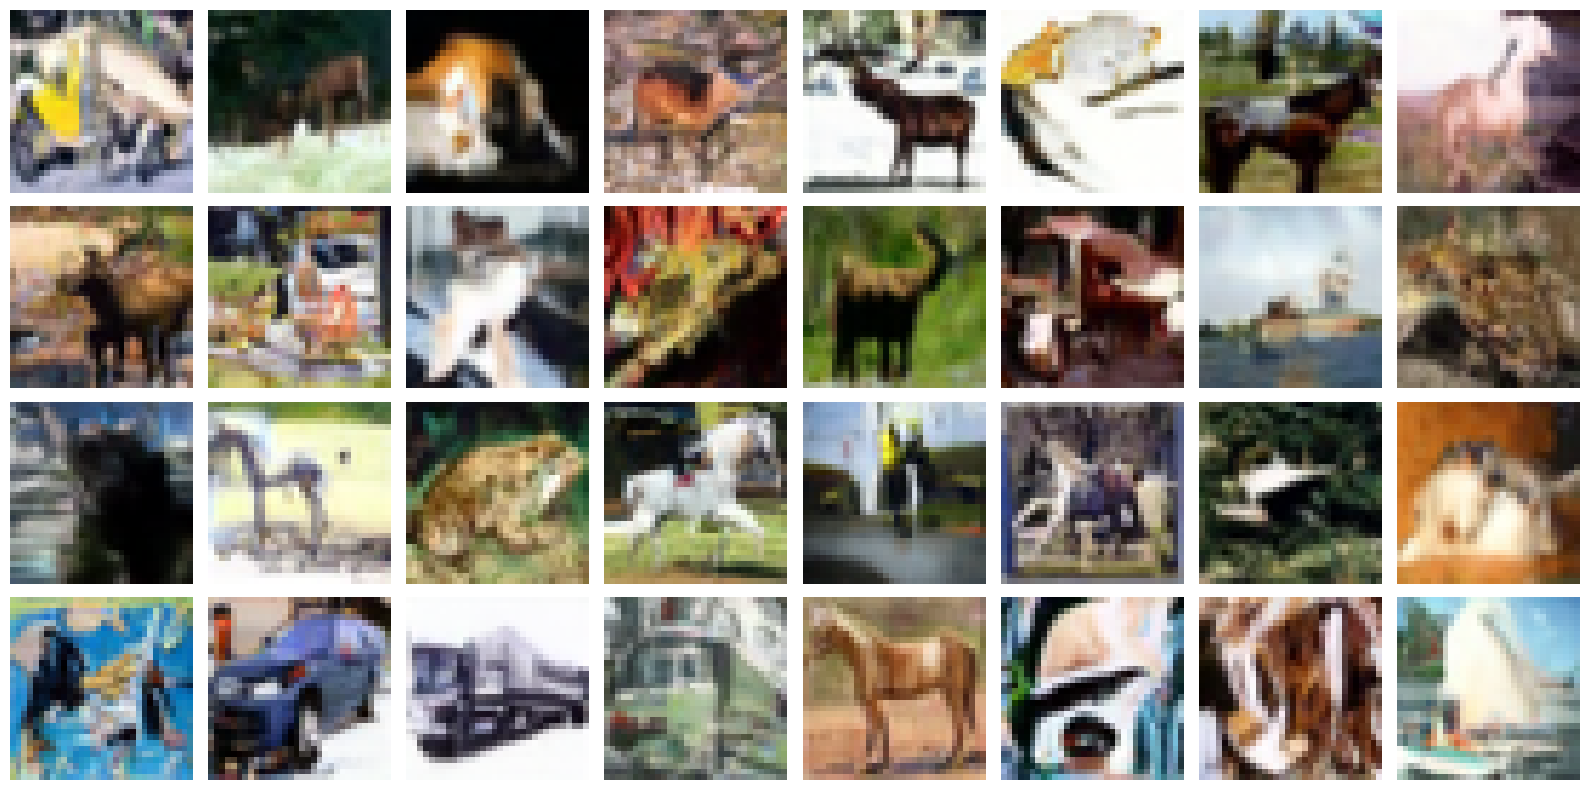

In [87]:
# openai images
import numpy as np
import matplotlib.pyplot as plt

# Load the data from the npz file
#file_path = '/workspace/aim-bridges-img/samples_32x32x32x3_40k.npz'
#file_path = '/workspace/aim-bridges-img/samples_1200x32x32x3.npz'
#file_path = '/workspace/aim-bridges-img/samples_1k_50000x32x32x3.npz'
file_path = '/workspace/aim-bridges-img/samples_ema_1k_40k_50000x32x32x3.npz'
data = np.load(file_path)

# Extract images from the loaded data
images = data['arr_0']

# Visualize the first 32 images
fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i])
    ax.axis('off')

plt.tight_layout()
plt.show()

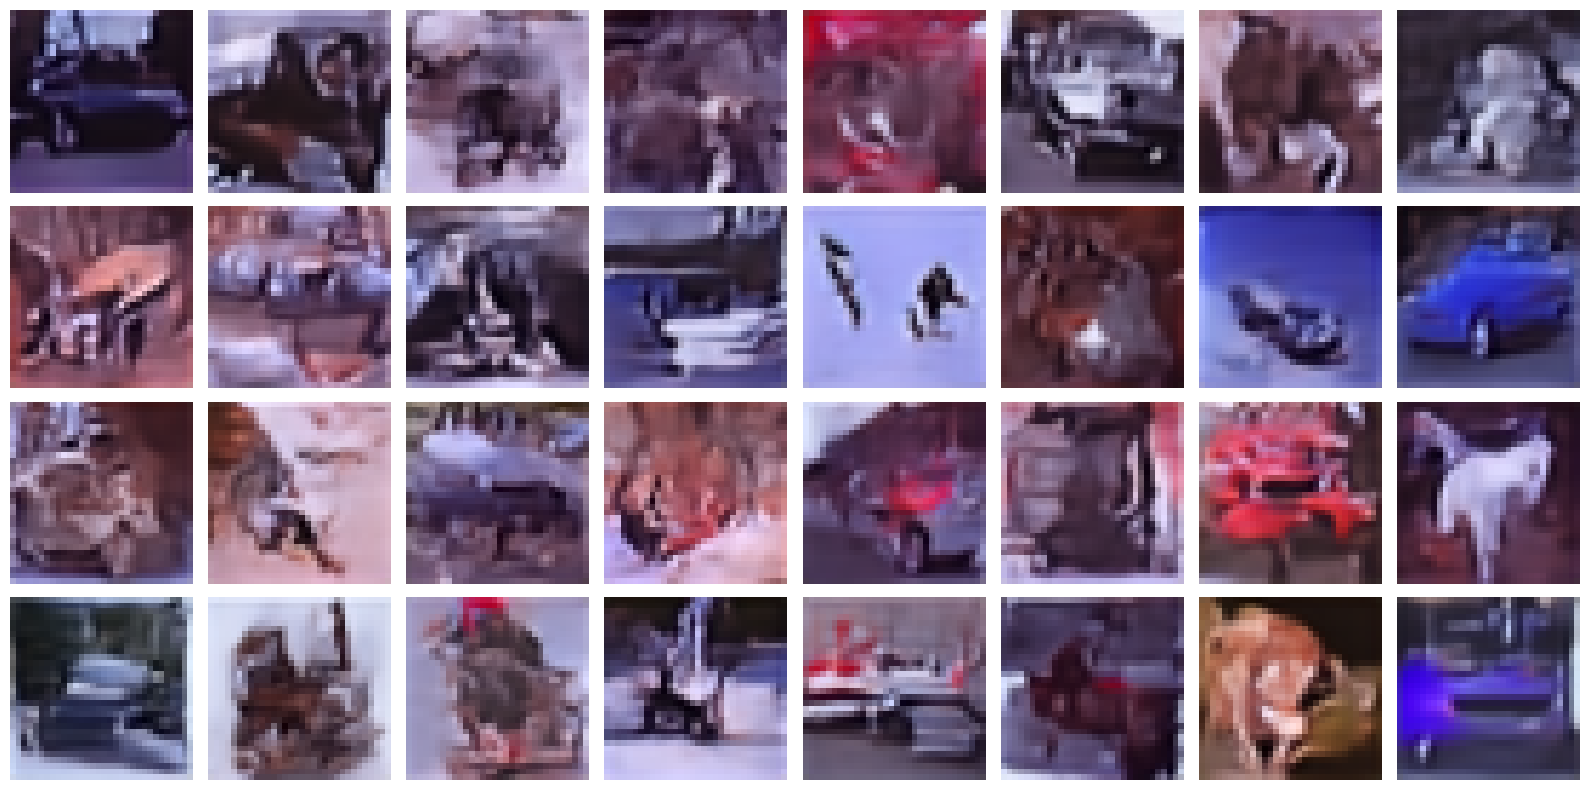

In [46]:
# bridge images
file_path = '/workspace/aim-bridges-img/bridge_50000_40k_1k_0.005_det.npz'
data = np.load(file_path)

bridge_images = data['images']
# Visualize the first 32 images
fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(bridge_images[i])
    ax.axis('off')

plt.tight_layout()
plt.show()

In [78]:
print(data.files)

['images']


In [47]:
def process_npz_image(image):
    # Assuming image is in shape (32, 32, 3) and needs to be transformed similarly
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Resize((299, 299)),  # Resize to the input size expected by Inception network
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])  # Normalize with ImageNet means and stds
    ])
    return transform(image)

def trivial_process_npz_image(image):
    # Assuming image is in shape (32, 32, 3) and needs to be transformed similarly
    transform = transforms.Compose([
        transforms.ToTensor()])
    return transform(image)

# Convert the images from npz to the required format and move to GPU
npz_images_processed = torch.stack([trivial_process_npz_image(image) for image in bridge_images]).to('cpu')
npz_images_processed_int = torch.stack([process_image(samp) for samp in npz_images_processed])

# Assuming `test_sample` and `train_sample_int` are already computed as per your initial code
# and are already on the CUDA device

# Initialize FID computation
fid = FrechetInceptionDistance().to('cpu')

chunk_size = 1000

# Chunk train samples
for batch_start in range(0, len(train_Y_int), chunk_size):
    batch_end = min(batch_start + chunk_size, len(train_Y_int))
    batch_chunk_train = train_Y_int[batch_start:batch_end]
    fid.update(batch_chunk_train, real=True)

    batch_chunk_model = npz_images_processed_int[batch_start:batch_end]
    fid.update(batch_chunk_model, real=False)


# Compute FID
fid_value = fid.compute()
print(f"FID: {fid_value.item()}")

FID: 88.3406753540039


In [36]:
samples.shape

torch.Size([50, 3, 32, 32])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i

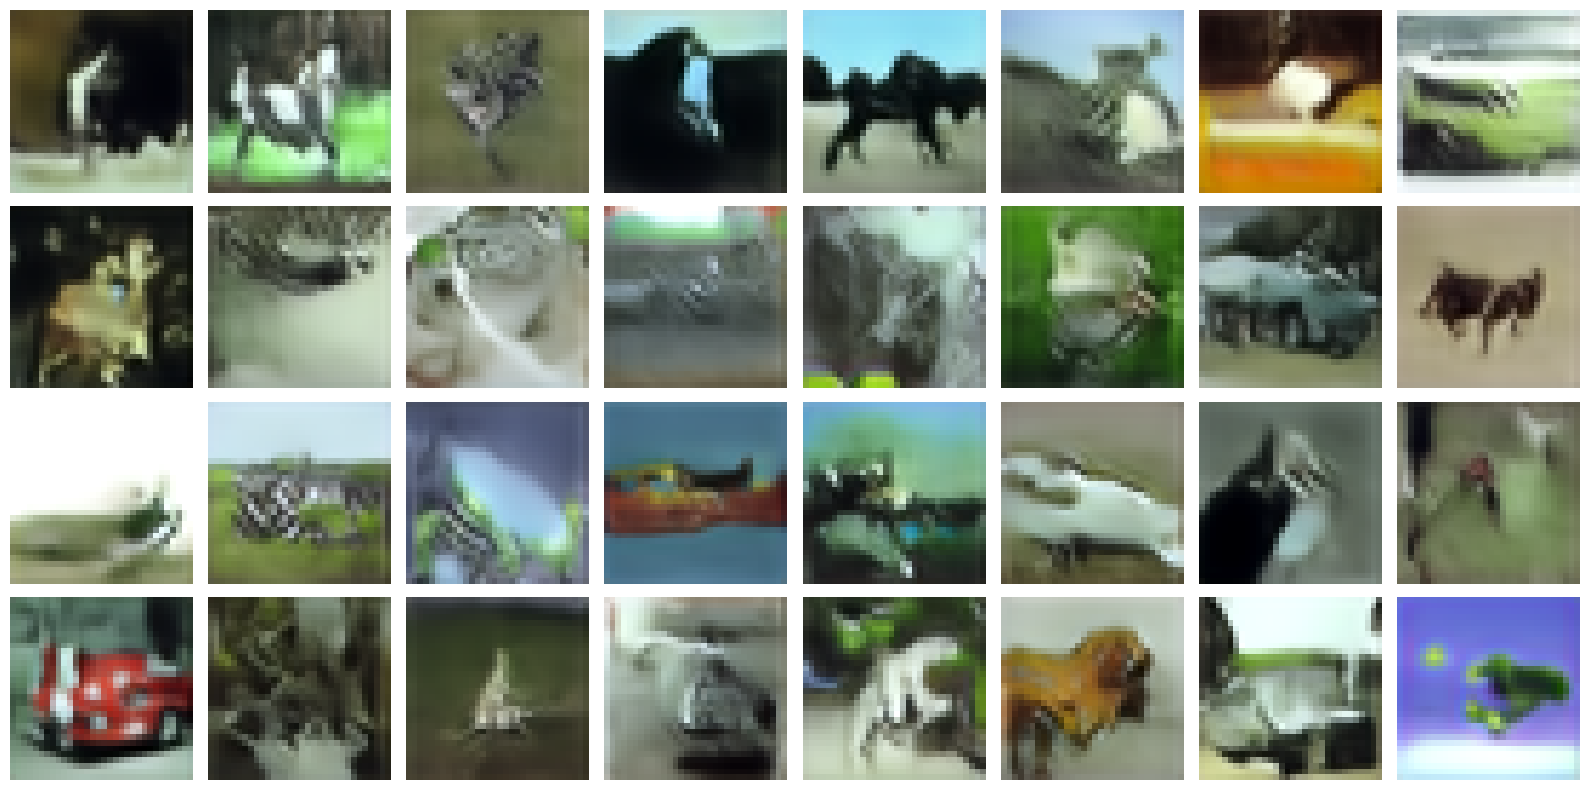

In [158]:
images_np = samples.cpu().permute(0, 2, 3, 1).numpy()

# Visualize the first 32 images
fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(images_np[i])
    ax.axis('off')

plt.tight_layout()
plt.show()